In [23]:
#!pip install --upgrade torch torchvision torchaudio

# FGSM (Fast Gradient Sign Method) Attack on Thermal Images

This notebook implements FGSM attacks on thermal images with epsilon values: ε = 0.01, 0.02, 0.03

**FGSM Attack Formula:**
- `x_adv = x + ε * sign(∇_x J(θ, x, y))`
- Where ε is the perturbation magnitude
- sign() is the sign function
- ∇_x J is the gradient of the loss with respect to the input


## Setup and Imports


In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.autograd import Variable
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os
from pathlib import Path
import cv2

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


PyTorch version: 2.9.1
CUDA available: False
Using device: cpu


## Load Thermal Image


Image loaded: 37.png
Image size: (320, 240)
Image mode: RGB
Image array shape: (240, 320, 3)
Image array dtype: uint8
Min pixel value: 0, Max pixel value: 255


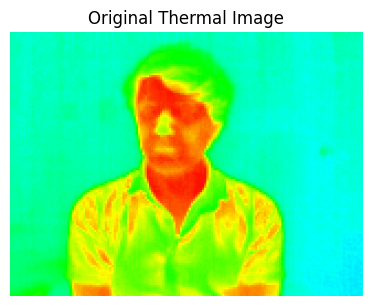

In [25]:
# Path to thermal image
image_path = "37.png"  # or "Application/thermalImage.jpg"

# Check if file exists, if not try alternative paths
if not os.path.exists(image_path):
    if os.path.exists("Application/thermalImage.jpg"):
        image_path = "Application/thermalImage.jpg"
    else:
        raise FileNotFoundError(f"Thermal image not found. Please provide a valid image path.")

# Load the image
image = Image.open(image_path).convert('RGB')
print(f"Image loaded: {image_path}")
print(f"Image size: {image.size}")
print(f"Image mode: {image.mode}")

# Convert to numpy array
image_array = np.array(image)
print(f"Image array shape: {image_array.shape}")
print(f"Image array dtype: {image_array.dtype}")
print(f"Min pixel value: {image_array.min()}, Max pixel value: {image_array.max()}")

# Display original image
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_array)
plt.title('Original Thermal Image')
plt.axis('off')
plt.show()


## Define a Simple Classifier Model

We'll use a simple CNN classifier as a surrogate model for the FGSM attack. This model can be trained or we can use a pre-trained model.


In [26]:
class SimpleThermalClassifier(nn.Module):
    """
    Simple CNN classifier for thermal images.
    This is a surrogate model for FGSM attack demonstration.
    """
    def __init__(self, num_classes=2):
        super(SimpleThermalClassifier, self).__init__()
        # Input: 3 channels (RGB), output: feature maps
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        
        # Adaptive pooling to handle different input sizes
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        
        # Fully connected layers
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(0.5)
        
    def forward(self, x):
        # Convolutional layers with ReLU and pooling
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv3(x))
        x = self.pool(x)
        
        # Flatten - use reshape instead of view to handle non-contiguous tensors
        x = x.reshape(x.size(0), -1)
        
        # Fully connected layers
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

# Initialize model
model = SimpleThermalClassifier(num_classes=2).to(device)
model.eval()  # Set to evaluation mode

# Initialize with random weights (in a real scenario, you would load trained weights)
# For demonstration, we'll use random initialization
print("Model initialized successfully")
print(f"Model parameters: {sum(p.numel() for p in model.parameters())} total parameters")


Model initialized successfully
Model parameters: 618306 total parameters


## Prepare Image for Model Input


In [27]:
def preprocess_image(image_array):
    """
    Preprocess image for model input.
    Converts numpy array to PyTorch tensor and normalizes.
    """
    # Convert to float and normalize to [0, 1]
    if image_array.dtype != np.float32:
        image_array = image_array.astype(np.float32) / 255.0
    
    # Convert HWC to CHW format
    if len(image_array.shape) == 3:
        image_tensor = torch.from_numpy(image_array).permute(2, 0, 1)
    else:
        image_tensor = torch.from_numpy(image_array).unsqueeze(0)
    
    # Add batch dimension
    image_tensor = image_tensor.unsqueeze(0)
    
    return image_tensor.to(device)

def postprocess_image(image_tensor):
    """
    Postprocess model output back to numpy array for visualization.
    """
    # Remove batch dimension and convert CHW to HWC
    image_array = image_tensor.squeeze(0).cpu().detach().numpy()
    
    # Convert CHW to HWC
    if len(image_array.shape) == 3 and image_array.shape[0] == 3:
        image_array = image_array.transpose(1, 2, 0)
    
    # Clip to [0, 1] and convert to uint8
    image_array = np.clip(image_array, 0, 1)
    image_array = (image_array * 255).astype(np.uint8)
    
    return image_array

# Preprocess the image
image_tensor = preprocess_image(image_array)
print(f"Preprocessed image tensor shape: {image_tensor.shape}")
print(f"Preprocessed image tensor range: [{image_tensor.min():.4f}, {image_tensor.max():.4f}]")


Preprocessed image tensor shape: torch.Size([1, 3, 240, 320])
Preprocessed image tensor range: [0.0000, 1.0000]


## FGSM Attack Implementation


In [28]:
def fgsm_attack(model, image, epsilon, target_label=None, loss_fn=nn.CrossEntropyLoss()):
    """
    Perform FGSM (Fast Gradient Sign Method) attack on an image.
    
    Parameters:
    -----------
    model : torch.nn.Module
        The neural network model to attack
    image : torch.Tensor
        Input image tensor (requires_grad=True)
    epsilon : float
        Perturbation magnitude (ε)
    target_label : int, optional
        Target label for targeted attack. If None, performs untargeted attack.
    loss_fn : torch.nn.Module
        Loss function to use
    
    Returns:
    --------
    perturbed_image : torch.Tensor
        Adversarially perturbed image
    perturbation : torch.Tensor
        The perturbation added to the image
    """
    # Ensure image requires gradient
    image.requires_grad = True
    
    # Forward pass
    output = model(image)
    
    # Get predicted label
    init_pred = output.max(1, keepdim=True)[1]
    
    # Determine target for loss calculation
    if target_label is None:
        # Untargeted attack: maximize loss (minimize negative loss)
        target = init_pred.item()
        loss = -loss_fn(output, torch.tensor([target]).to(device))
    else:
        # Targeted attack: minimize loss for target class
        loss = loss_fn(output, torch.tensor([target_label]).to(device))
    
    # Backward pass to compute gradients
    model.zero_grad()
    loss.backward()
    
    # Get gradient of loss with respect to input
    image_grad = image.grad.data
    
    # Compute perturbation: ε * sign(∇_x J)
    perturbation = epsilon * image_grad.sign()
    
    # Create adversarial example: x_adv = x + ε * sign(∇_x J)
    perturbed_image = image + perturbation
    
    # Clip to valid range [0, 1]
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    
    return perturbed_image, perturbation

print("FGSM attack function defined successfully")


FGSM attack function defined successfully


In [29]:
# Epsilon values for FGSM attacks
epsilon_values = [0.01, 0.02, 0.03, 0.1, 0.2, 0.3, 0.5]

# Store results
attack_results = {}

# Get initial prediction
with torch.no_grad():
    initial_output = model(image_tensor)
    initial_pred = initial_output.max(1, keepdim=True)[1].item()
    initial_confidence = F.softmax(initial_output, dim=1)[0, initial_pred].item()

print(f"Initial prediction: Class {initial_pred} with confidence: {initial_confidence:.4f}")
print(f"Initial output logits: {initial_output.squeeze().cpu().numpy()}")
print("\n" + "="*60)
print("Performing FGSM attacks...")
print("="*60)

for epsilon in epsilon_values:
    print(f"\nProcessing ε = {epsilon}...")
    
    # Create a fresh copy of the image tensor for this attack
    image_tensor_copy = image_tensor.clone().detach()
    
    # Perform FGSM attack
    perturbed_tensor, perturbation = fgsm_attack(
        model, 
        image_tensor_copy, 
        epsilon=epsilon
    )
    
    # Get prediction on perturbed image
    with torch.no_grad():
        perturbed_output = model(perturbed_tensor)
        perturbed_pred = perturbed_output.max(1, keepdim=True)[1].item()
        perturbed_confidence = F.softmax(perturbed_output, dim=1)[0, perturbed_pred].item()
    
    # Convert to numpy for visualization
    perturbed_array = postprocess_image(perturbed_tensor)
    perturbation_array = postprocess_image(perturbation)
    
    # Calculate statistics
    perturbation_magnitude = torch.norm(perturbation).item()
    max_perturbation = perturbation.abs().max().item()
    
    # Store results
    attack_results[epsilon] = {
        'perturbed_image': perturbed_array,
        'perturbation': perturbation_array,
        'perturbed_tensor': perturbed_tensor,
        'initial_pred': initial_pred,
        'perturbed_pred': perturbed_pred,
        'initial_confidence': initial_confidence,
        'perturbed_confidence': perturbed_confidence,
        'perturbation_magnitude': perturbation_magnitude,
        'max_perturbation': max_perturbation,
        'prediction_changed': initial_pred != perturbed_pred
    }
    
    print(f"  ✓ Attack completed")
    print(f"  Initial prediction: Class {initial_pred} (confidence: {initial_confidence:.4f})")
    print(f"  Perturbed prediction: Class {perturbed_pred} (confidence: {perturbed_confidence:.4f})")
    print(f"  Prediction changed: {initial_pred != perturbed_pred}")
    print(f"  Perturbation magnitude: {perturbation_magnitude:.6f}")
    print(f"  Max perturbation value: {max_perturbation:.6f}")

print("\n" + "="*60)
print("All FGSM attacks completed!")
print("="*60)


Initial prediction: Class 1 with confidence: 0.5149
Initial output logits: [-0.05260324  0.00711548]

Performing FGSM attacks...

Processing ε = 0.01...
  ✓ Attack completed
  Initial prediction: Class 1 (confidence: 0.5149)
  Perturbed prediction: Class 1 (confidence: 0.5153)
  Prediction changed: False
  Perturbation magnitude: 4.800230
  Max perturbation value: 0.010000

Processing ε = 0.02...
  ✓ Attack completed
  Initial prediction: Class 1 (confidence: 0.5149)
  Perturbed prediction: Class 1 (confidence: 0.5155)
  Prediction changed: False
  Perturbation magnitude: 9.600460
  Max perturbation value: 0.020000

Processing ε = 0.03...
  ✓ Attack completed
  Initial prediction: Class 1 (confidence: 0.5149)
  Perturbed prediction: Class 1 (confidence: 0.5156)
  Prediction changed: False
  Perturbation magnitude: 14.401700
  Max perturbation value: 0.030000

Processing ε = 0.1...
  ✓ Attack completed
  Initial prediction: Class 1 (confidence: 0.5149)
  Perturbed prediction: Class 1 (c

## Visualize Results


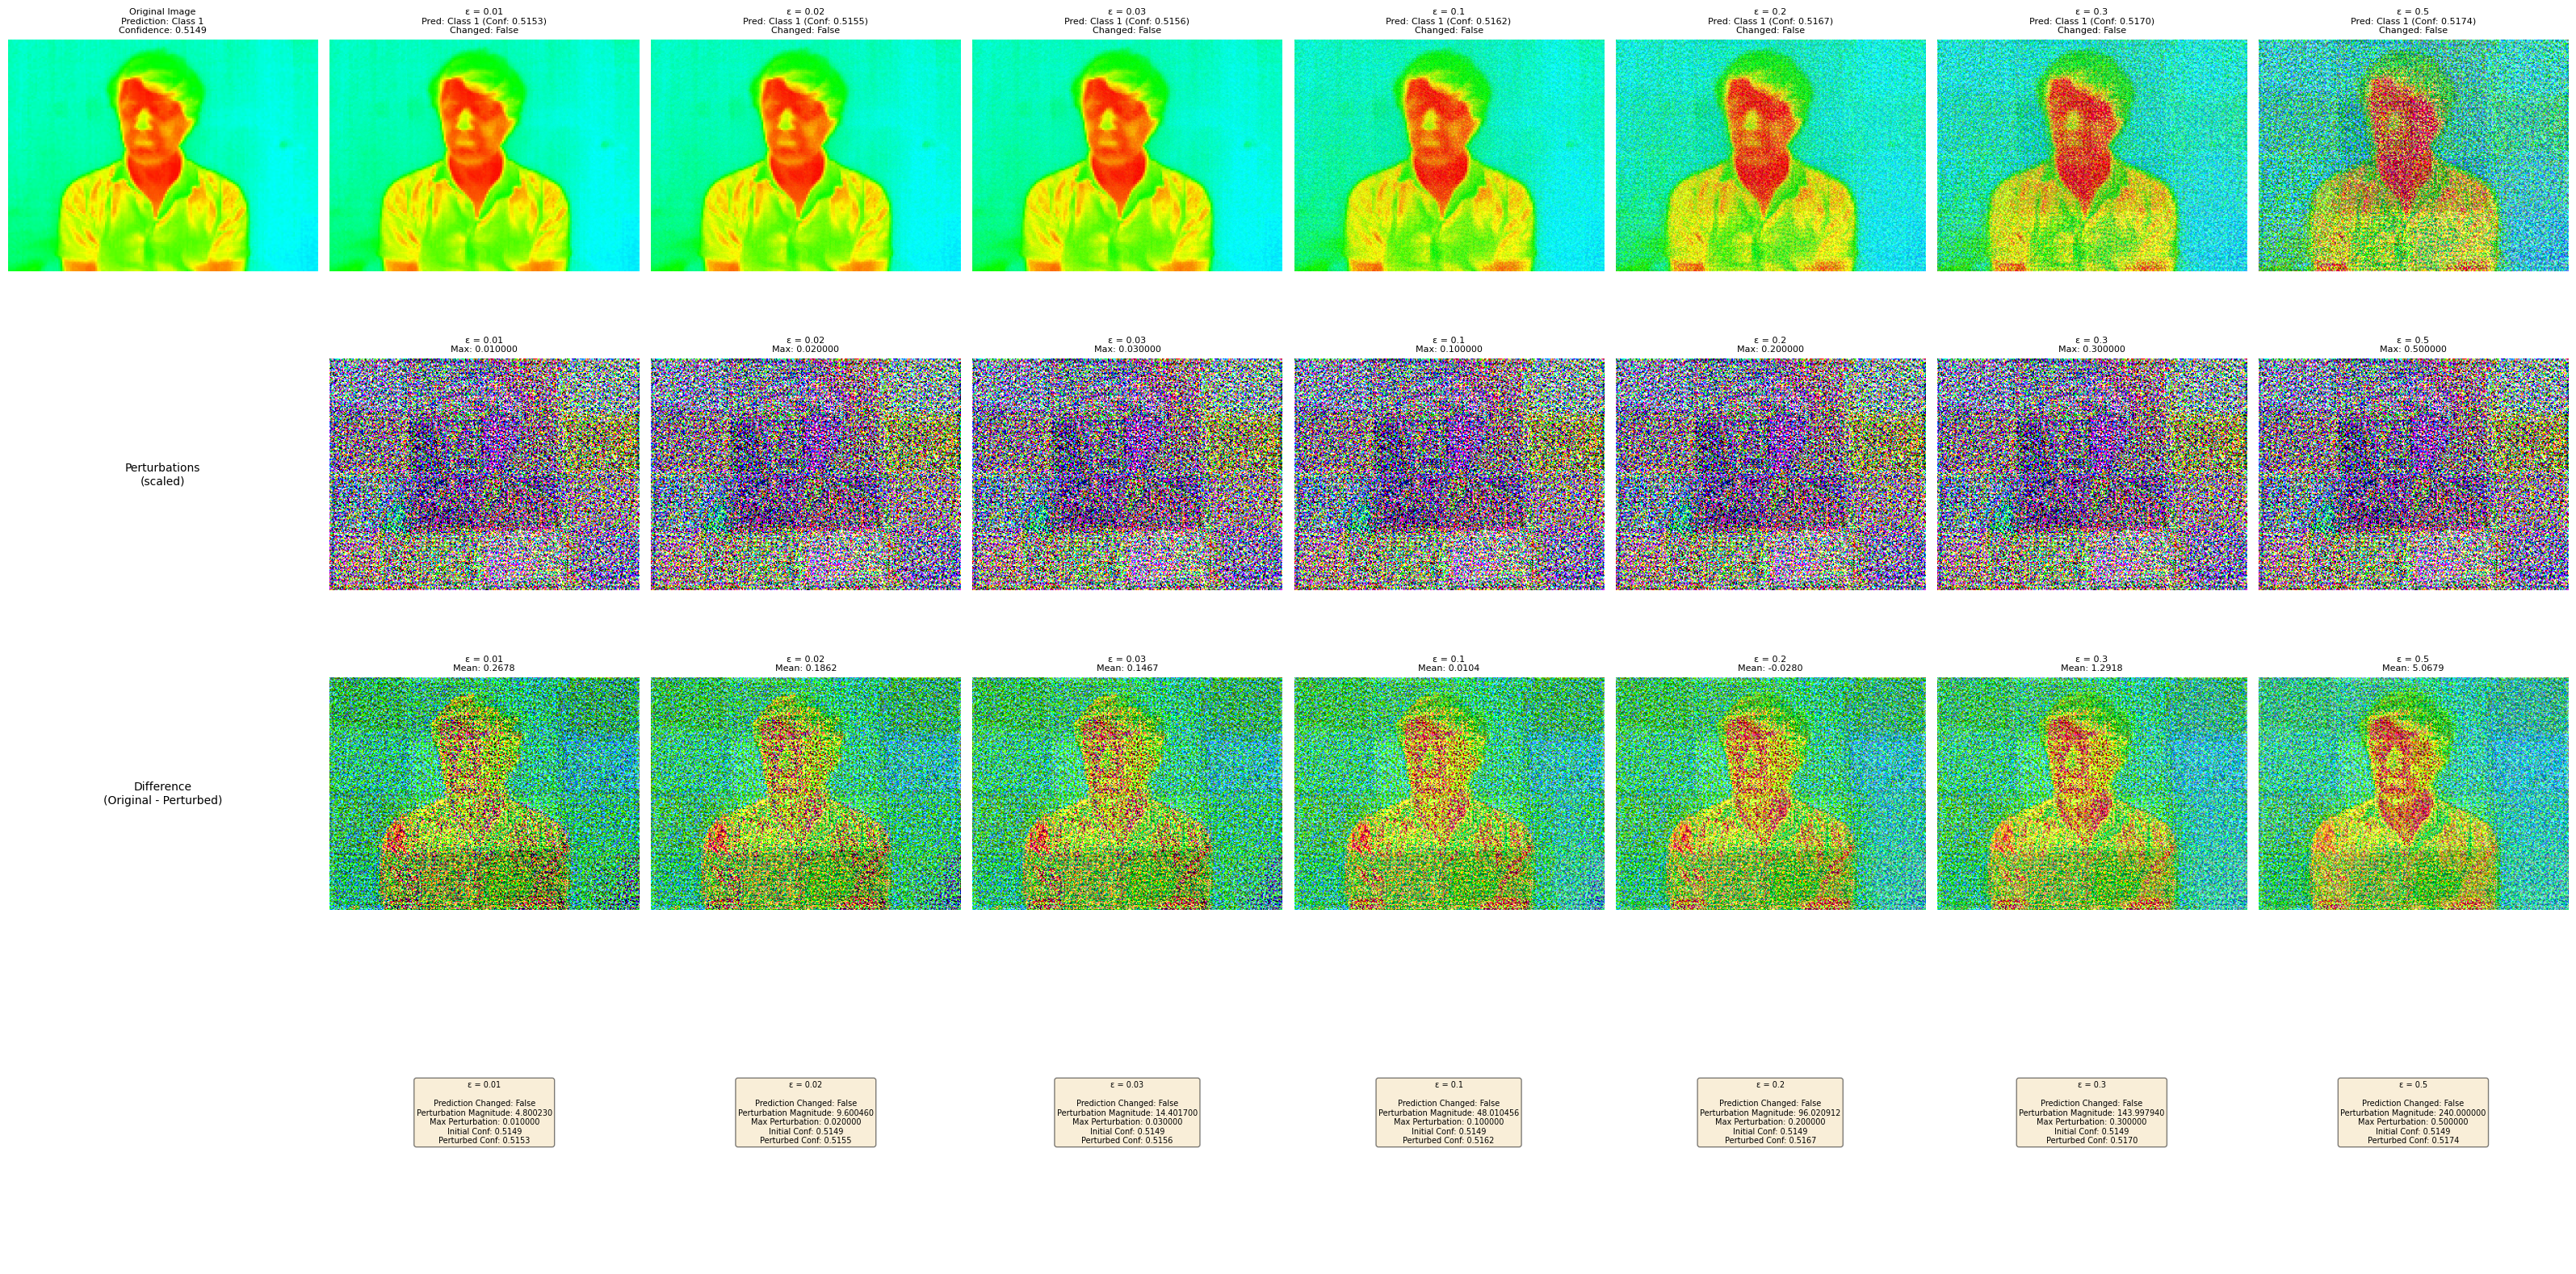

In [30]:
# Create comprehensive visualization
# Adjust figure size based on number of epsilon values
num_eps = len(epsilon_values)
fig_width = min(4 * (num_eps + 1), 60)  # Cap width at 60 inches
fig, axes = plt.subplots(4, num_eps + 1, figsize=(fig_width, 16))

# Original image
axes[0, 0].imshow(image_array)
axes[0, 0].set_title(f'Original Image\nPrediction: Class {initial_pred}\nConfidence: {initial_confidence:.4f}', fontsize=8)
axes[0, 0].axis('off')

# Row 1: Perturbed images
for idx, epsilon in enumerate(epsilon_values, 1):
    result = attack_results[epsilon]
    axes[0, idx].imshow(result['perturbed_image'])
    title = f'ε = {epsilon}\nPred: Class {result["perturbed_pred"]} (Conf: {result["perturbed_confidence"]:.4f})\nChanged: {result["prediction_changed"]}'
    axes[0, idx].set_title(title, fontsize=8)
    axes[0, idx].axis('off')

# Row 2: Perturbations (scaled for visualization)
axes[1, 0].text(0.5, 0.5, 'Perturbations\n(scaled)', ha='center', va='center', fontsize=10)
axes[1, 0].axis('off')

for idx, epsilon in enumerate(epsilon_values, 1):
    result = attack_results[epsilon]
    # Scale perturbation for visualization (multiply by 10 to make it visible)
    perturbation_vis = np.clip((result['perturbation'] - result['perturbation'].min()) / 
                                (result['perturbation'].max() - result['perturbation'].min() + 1e-8) * 255, 0, 255).astype(np.uint8)
    axes[1, idx].imshow(perturbation_vis)
    axes[1, idx].set_title(f'ε = {epsilon}\nMax: {result["max_perturbation"]:.6f}', fontsize=8)
    axes[1, idx].axis('off')

# Row 3: Difference images
axes[2, 0].text(0.5, 0.5, 'Difference\n(Original - Perturbed)', ha='center', va='center', fontsize=10)
axes[2, 0].axis('off')

for idx, epsilon in enumerate(epsilon_values, 1):
    result = attack_results[epsilon]
    difference = image_array.astype(float) - result['perturbed_image'].astype(float)
    # Normalize difference for visualization
    diff_normalized = (difference - difference.min()) / (difference.max() - difference.min() + 1e-8)
    axes[2, idx].imshow(diff_normalized, cmap='seismic')
    axes[2, idx].set_title(f'ε = {epsilon}\nMean: {difference.mean():.4f}', fontsize=8)
    axes[2, idx].axis('off')

# Row 4: Statistics
axes[3, 0].axis('off')

for idx, epsilon in enumerate(epsilon_values, 1):
    result = attack_results[epsilon]
    stats_text = f"ε = {epsilon}\n\n"
    stats_text += f"Prediction Changed: {result['prediction_changed']}\n"
    stats_text += f"Perturbation Magnitude: {result['perturbation_magnitude']:.6f}\n"
    stats_text += f"Max Perturbation: {result['max_perturbation']:.6f}\n"
    stats_text += f"Initial Conf: {result['initial_confidence']:.4f}\n"
    stats_text += f"Perturbed Conf: {result['perturbed_confidence']:.4f}"
    
    axes[3, idx].text(0.5, 0.5, stats_text, ha='center', va='center', fontsize=7, 
                      bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    axes[3, idx].axis('off')

plt.tight_layout()
plt.show()


## Detailed Statistics


In [31]:
print("="*60)
print("FGSM Attack Statistics")
print("="*60)
print(f"\nOriginal Image:")
print(f"  Prediction: Class {initial_pred}")
print(f"  Confidence: {initial_confidence:.4f}")
print(f"  Image shape: {image_array.shape}")
print(f"  Pixel value range: [{image_array.min()}, {image_array.max()}]")

print("\n" + "-"*60)
for epsilon in epsilon_values:
    result = attack_results[epsilon]
    difference = image_array.astype(float) - result['perturbed_image'].astype(float)
    
    print(f"\nε = {epsilon}:")
    print(f"  Prediction: Class {result['perturbed_pred']} (was Class {result['initial_pred']})")
    print(f"  Prediction changed: {result['prediction_changed']}")
    print(f"  Confidence: {result['perturbed_confidence']:.4f} (was {result['initial_confidence']:.4f})")
    print(f"  Perturbation magnitude (L2 norm): {result['perturbation_magnitude']:.6f}")
    print(f"  Max perturbation value: {result['max_perturbation']:.6f}")
    print(f"  Difference statistics:")
    print(f"    Mean: {difference.mean():.6f}")
    print(f"    Std: {difference.std():.6f}")
    print(f"    Min: {difference.min():.6f}")
    print(f"    Max: {difference.max():.6f}")
    print(f"    Non-zero pixels: {np.count_nonzero(difference)}")

print("\n" + "="*60)


FGSM Attack Statistics

Original Image:
  Prediction: Class 1
  Confidence: 0.5149
  Image shape: (240, 320, 3)
  Pixel value range: [0, 255]

------------------------------------------------------------

ε = 0.01:
  Prediction: Class 1 (was Class 1)
  Prediction changed: False
  Confidence: 0.5153 (was 0.5149)
  Perturbation magnitude (L2 norm): 4.800230
  Max perturbation value: 0.010000
  Difference statistics:
    Mean: 0.267847
    Std: 2.113061
    Min: -2.000000
    Max: 3.000000
    Non-zero pixels: 168959

ε = 0.02:
  Prediction: Class 1 (was Class 1)
  Prediction changed: False
  Confidence: 0.5155 (was 0.5149)
  Perturbation magnitude (L2 norm): 9.600460
  Max perturbation value: 0.020000
  Difference statistics:
    Mean: 0.186155
    Std: 4.570819
    Min: -5.000000
    Max: 6.000000
    Non-zero pixels: 168959

ε = 0.03:
  Prediction: Class 1 (was Class 1)
  Prediction changed: False
  Confidence: 0.5156 (was 0.5149)
  Perturbation magnitude (L2 norm): 14.401700
  Max per

## Save Adversarial Images


In [32]:
# Save all adversarial images
input_name = Path(image_path).stem
input_ext = Path(image_path).suffix

print("Saving adversarial images...")
print("="*60)

for epsilon in epsilon_values:
    result = attack_results[epsilon]
    
    # Format epsilon for filename: use integer if whole number, otherwise 2 decimal places
    if epsilon == int(epsilon):
        eps_str = str(int(epsilon))
    else:
        eps_str = f"{epsilon:.2f}"
    
    # Save perturbed image
    perturbed_image = Image.fromarray(result['perturbed_image'])
    output_filename = f"{input_name}_fgsm_eps{eps_str}{input_ext}"
    perturbed_image.save(output_filename)
    print(f"✓ Saved: {output_filename}")
    
    # Save perturbation visualization (optional)
    perturbation_vis = np.clip((result['perturbation'] - result['perturbation'].min()) / 
                              (result['perturbation'].max() - result['perturbation'].min() + 1e-8) * 255, 
                              0, 255).astype(np.uint8)
    perturbation_image = Image.fromarray(perturbation_vis)
    perturbation_filename = f"{input_name}_fgsm_perturbation_eps{eps_str}{input_ext}"
    perturbation_image.save(perturbation_filename)
    print(f"✓ Saved: {perturbation_filename}")
    
    # Save difference image (Original - Perturbed)
    difference = image_array.astype(float) - result['perturbed_image'].astype(float)
    # Normalize difference for visualization (scale to 0-255 range)
    diff_normalized = (difference - difference.min()) / (difference.max() - difference.min() + 1e-8)
    diff_vis = (diff_normalized * 255).astype(np.uint8)
    difference_image = Image.fromarray(diff_vis)
    difference_filename = f"{input_name}_fgsm_difference_eps{eps_str}{input_ext}"
    difference_image.save(difference_filename)
    print(f"✓ Saved: {difference_filename}")

print("="*60)
print("All adversarial images saved successfully!")


Saving adversarial images...
✓ Saved: 37_fgsm_eps0.01.png
✓ Saved: 37_fgsm_perturbation_eps0.01.png
✓ Saved: 37_fgsm_difference_eps0.01.png
✓ Saved: 37_fgsm_eps0.02.png
✓ Saved: 37_fgsm_perturbation_eps0.02.png
✓ Saved: 37_fgsm_difference_eps0.02.png
✓ Saved: 37_fgsm_eps0.03.png
✓ Saved: 37_fgsm_perturbation_eps0.03.png
✓ Saved: 37_fgsm_difference_eps0.03.png
✓ Saved: 37_fgsm_eps0.10.png
✓ Saved: 37_fgsm_perturbation_eps0.10.png
✓ Saved: 37_fgsm_difference_eps0.10.png
✓ Saved: 37_fgsm_eps0.20.png
✓ Saved: 37_fgsm_perturbation_eps0.20.png
✓ Saved: 37_fgsm_difference_eps0.20.png
✓ Saved: 37_fgsm_eps0.30.png
✓ Saved: 37_fgsm_perturbation_eps0.30.png
✓ Saved: 37_fgsm_difference_eps0.30.png
✓ Saved: 37_fgsm_eps0.50.png
✓ Saved: 37_fgsm_perturbation_eps0.50.png
✓ Saved: 37_fgsm_difference_eps0.50.png
All adversarial images saved successfully!


## Comparison Plot: Confidence vs Epsilon


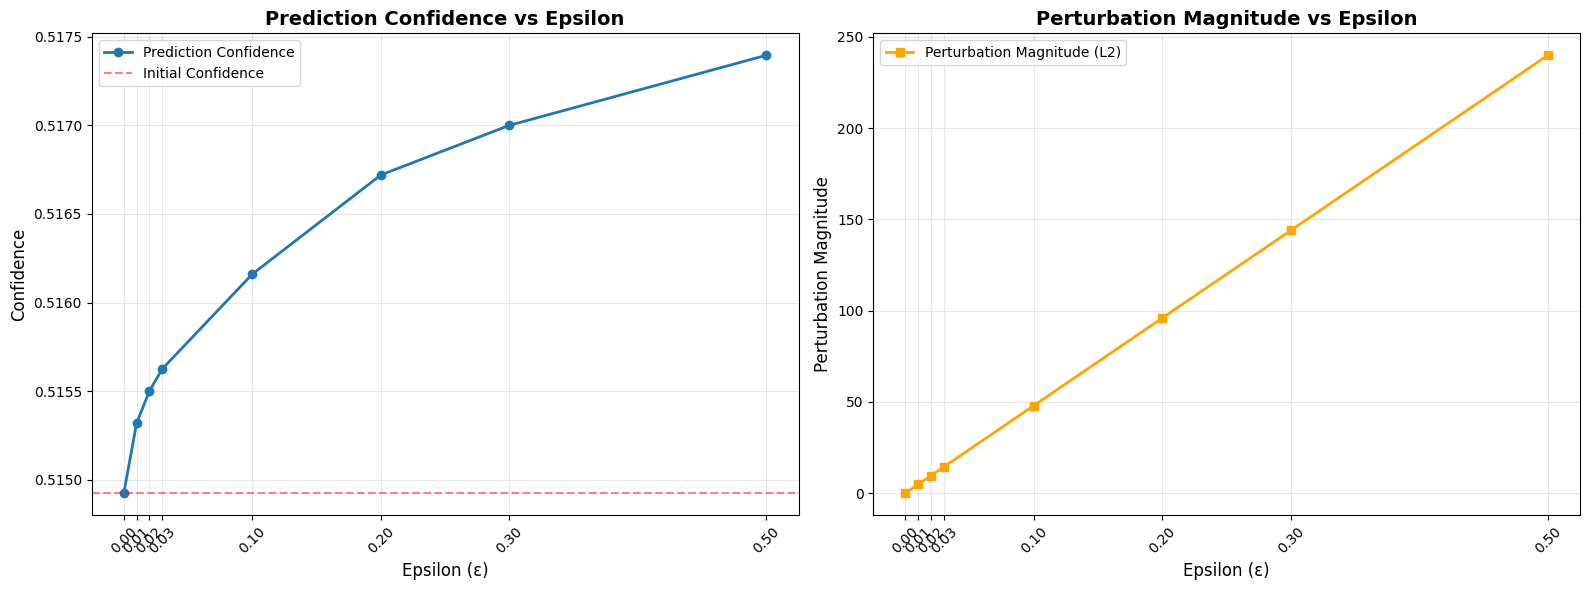


Summary:
  Initial confidence: 0.5149
  ε = 0.01: Confidence = 0.5153, Changed = ✗
  ε = 0.02: Confidence = 0.5155, Changed = ✗
  ε = 0.03: Confidence = 0.5156, Changed = ✗
  ε = 0.1: Confidence = 0.5162, Changed = ✗
  ε = 0.2: Confidence = 0.5167, Changed = ✗
  ε = 0.3: Confidence = 0.5170, Changed = ✗
  ε = 0.5: Confidence = 0.5174, Changed = ✗


In [33]:
# Plot confidence changes
epsilons = [0] + epsilon_values
confidences = [initial_confidence] + [attack_results[eps]['perturbed_confidence'] for eps in epsilon_values]
prediction_changes = [False] + [attack_results[eps]['prediction_changed'] for eps in epsilon_values]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Confidence vs Epsilon
ax1.plot(epsilons, confidences, 'o-', linewidth=2, markersize=6, label='Prediction Confidence')
ax1.axhline(y=initial_confidence, color='r', linestyle='--', alpha=0.5, label='Initial Confidence')
ax1.set_xlabel('Epsilon (ε)', fontsize=12)
ax1.set_ylabel('Confidence', fontsize=12)
ax1.set_title('Prediction Confidence vs Epsilon', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()
ax1.set_xticks(epsilons)
ax1.tick_params(axis='x', rotation=45)

# Plot 2: Perturbation Magnitude vs Epsilon
perturbation_magnitudes = [0] + [attack_results[eps]['perturbation_magnitude'] for eps in epsilon_values]
ax2.plot(epsilons, perturbation_magnitudes, 's-', linewidth=2, markersize=6, color='orange', label='Perturbation Magnitude (L2)')
ax2.set_xlabel('Epsilon (ε)', fontsize=12)
ax2.set_ylabel('Perturbation Magnitude', fontsize=12)
ax2.set_title('Perturbation Magnitude vs Epsilon', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()
ax2.set_xticks(epsilons)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Print summary
print("\nSummary:")
print(f"  Initial confidence: {initial_confidence:.4f}")
for epsilon in epsilon_values:
    result = attack_results[epsilon]
    change = "✓" if result['prediction_changed'] else "✗"
    print(f"  ε = {epsilon}: Confidence = {result['perturbed_confidence']:.4f}, Changed = {change}")
